# Cats or Dogs: When Is Feature Extraction Enough?

This notebook asks when a frozen ImageNet backbone is already enough, and when the last block still needs a small nudge, on a handful of labeled pet photos. The set is a 10-breed slice of Oxford-IIIT Pet: five cats and five dogs.

Run it in Colab on a T4: **Runtime → Change runtime type → T4 GPU**, then **Runtime → Run all**.

- **B1** trains ResNet-18 from scratch.
- **B2** freezes the ImageNet backbone and trains only the new head.
- **B3** unfreezes `layer4` at a lower learning rate, with augmentation left on. This is the run we keep.
- **B4** drops that augmentation, so we can see what the random crops and color changes were worth.
- **B5** applies the same fine-tune to EfficientNet-B0, which updates far fewer weights.
- The last section reads `layer4` before fine-tuning (B2) and after it (B3). The maps barely move, which is why the extra gain over a frozen backbone is small.

One protocol for all five runs: 224 input, ImageNet normalization, batch 32, AdamW, cross-entropy, seed 42, early stop on validation loss (patience 4, at most 15 epochs), stratified 70/15/15.

The last cell zips `outputs/`. Run from the top. Later cells expect the models trained above.


## 1. Setup

Imports, one seed, and the output folder. If this prints `cpu`, switch Colab to a T4 and run again from the top.


In [1]:
# Seed, ImageNet normalization, and the output folder. Colab writes under /content.
import copy
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from PIL import Image
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms
from torchvision.datasets import OxfordIIITPet

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "legend.frameon": False,
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})
TRAIN_COLOR = "#1B4F72"
VAL_COLOR = "#C0392B"
BAR_COLOR = "#1B4F72"
BAR_HIGHLIGHT = "#B9770E"

SEED = 42
BATCH_SIZE = 32
MAX_EPOCHS = 15
PATIENCE = 4
NUM_CLASSES = 10
RUN_B5 = True
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

ROOT = Path("/content") if Path("/content").exists() else Path(".").resolve()
DATA_DIR = ROOT / "data"
OUT_DIR = ROOT / "outputs"
OUT_DIR.mkdir(parents=True, exist_ok=True)

CATS = ["Abyssinian", "Bengal", "Birman", "Bombay", "British Shorthair"]
DOGS = [
    "American Bulldog",
    "American Pit Bull Terrier",
    "Basset Hound",
    "Beagle",
    "Boxer",
]
SELECTED = CATS + DOGS


def set_seed(seed: int = SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type != "cuda":
    print("No GPU detected. In Colab use Runtime → Change runtime type → T4 GPU, then rerun from the top.")
print("device", DEVICE)
print("outputs", OUT_DIR)


device cuda
outputs /content/outputs


## 2. Data

Both official pools are kept, then cut to five cat breeds and five dog breeds. One stratified 70/15/15 split. A photo is never in more than one of train, validation, and test.


In [2]:
# Keep the 10 breeds, then split 70/15/15. One photo stays in one set.
class PetSubset(Dataset):
    def __init__(self, samples, transform):
        self.samples = samples
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        path, label = self.samples[index]
        image = Image.open(path).convert("RGB")
        if self.transform is not None:
            image = self.transform(image)
        return image, label


def collect_selected(dataset, selected):
    selected = set(selected)
    rows = []
    for path, label in zip(dataset._images, dataset._labels):
        name = dataset.classes[label]
        if name in selected:
            rows.append((path, name))
    return rows


trainval = OxfordIIITPet(root=DATA_DIR, split="trainval", download=True)
test_split = OxfordIIITPet(root=DATA_DIR, split="test", download=True)
missing = [name for name in SELECTED if name not in trainval.classes]
if missing:
    raise RuntimeError(f"Class names not in OxfordIIITPet: {missing}. Available: {trainval.classes}")

records = collect_selected(trainval, SELECTED) + collect_selected(test_split, SELECTED)
label_to_index = {name: i for i, name in enumerate(SELECTED)}
index_to_label = {i: name for name, i in label_to_index.items()}
samples = [(path, label_to_index[name]) for path, name in records]
labels = np.array([label for _, label in samples])

train_idx, holdout_idx = train_test_split(
    np.arange(len(samples)), test_size=0.30, stratify=labels, random_state=SEED
)
val_idx, test_idx = train_test_split(
    holdout_idx, test_size=0.50, stratify=labels[holdout_idx], random_state=SEED
)

def take(indices):
    return [samples[i] for i in indices]

train_samples, val_samples, test_samples = take(train_idx), take(val_idx), take(test_idx)
print(
    f"images {len(samples)} | train {len(train_samples)} | "
    f"val {len(val_samples)} | test {len(test_samples)}"
)
print("classes", SELECTED)


100%|██████████| 792M/792M [00:36<00:00, 21.9MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 10.1MB/s]


images 1981 | train 1386 | val 297 | test 298
classes ['Abyssinian', 'Bengal', 'Birman', 'Bombay', 'British Shorthair', 'American Bulldog', 'American Pit Bull Terrier', 'Basset Hound', 'Beagle', 'Boxer']


## 3. Transforms

Training uses resize, random crop, horizontal flip, a 15 degree rotation, and color jitter, then ImageNet normalization. Validation and test use the eval transform only. The plain training loader is the same eval transform, for the run without augmentation.


In [3]:
# Augment training only. Validation, test, and the plain loader use the eval transform.
weights = models.ResNet18_Weights.IMAGENET1K_V1

train_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=weights.transforms().mean, std=weights.transforms().std),
])

eval_transform = weights.transforms()


def make_loader(samples, transform, shuffle):
    generator = torch.Generator()
    generator.manual_seed(SEED)
    return DataLoader(
        PetSubset(samples, transform),
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        num_workers=2 if DEVICE.type == "cuda" else 0,
        generator=generator if shuffle else None,
    )


train_loader_aug = make_loader(train_samples, train_transform, shuffle=True)
train_loader_plain = make_loader(train_samples, eval_transform, shuffle=True)
val_loader = make_loader(val_samples, eval_transform, shuffle=False)
test_loader = make_loader(test_samples, eval_transform, shuffle=False)


## 4. Models and the training loop

- **B1:** random weights, every parameter trainable, learning rate `1e-3`.
- **B2:** ImageNet weights, backbone frozen, new `Linear(512, 10)`. Trainable count is 5,130.
- **B3:** same pretrained network, `layer4` at `1e-4` and the head at `1e-3`.

Training uses AdamW and cross-entropy. It stops after 4 epochs without a better validation loss, then reloads the best checkpoint before the test score.


In [4]:
# B1 from scratch, B2 frozen head, B3 unfreezes layer4 at a lower learning rate.
# Stop when validation loss stalls, then reload the best weights before testing.
def count_trainable(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def build_resnet(recipe: str):
    """recipe is B1, B2, or B3. Returns model, AdamW parameter groups, and an lr label."""
    if recipe == "B1":
        model = models.resnet18(weights=None)
        model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
        groups = [{"params": [p for p in model.parameters() if p.requires_grad], "lr": 1e-3}]
        lr_label = "1e-3"
    elif recipe == "B2":
        model = models.resnet18(weights=weights)
        for param in model.parameters():
            param.requires_grad = False
        model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
        groups = [{"params": list(model.fc.parameters()), "lr": 1e-3}]
        lr_label = "1e-3"
    elif recipe == "B3":
        model = models.resnet18(weights=weights)
        for param in model.parameters():
            param.requires_grad = False
        for param in model.layer4.parameters():
            param.requires_grad = True
        model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
        groups = [
            {"params": list(model.layer4.parameters()), "lr": 1e-4},
            {"params": list(model.fc.parameters()), "lr": 1e-3},
        ]
        lr_label = "layer4=1e-4, fc=1e-3"
    else:
        raise ValueError(recipe)
    trainable = count_trainable(model)
    if recipe == "B2" and trainable != 5130:
        raise RuntimeError(f"B2 trainable count is {trainable}, expected 5130")
    return model, groups, lr_label, trainable


def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss = 0.0
    correct = 0
    seen = 0
    for images, targets in loader:
        images = images.to(DEVICE)
        targets = targets.to(DEVICE)
        if training:
            optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            logits = model(images)
            loss = criterion(logits, targets)
            if training:
                loss.backward()
                optimizer.step()
        total_loss += loss.item() * images.size(0)
        correct += (logits.argmax(dim=1) == targets).sum().item()
        seen += images.size(0)
    return total_loss / seen, correct / seen


@torch.no_grad()
def predict(model, loader):
    model.eval()
    pred_all = []
    true_all = []
    prob_all = []
    for images, targets in loader:
        logits = model(images.to(DEVICE))
        probs = torch.softmax(logits, dim=1)
        conf, pred = probs.max(dim=1)
        pred_all.append(pred.cpu())
        true_all.append(targets)
        prob_all.append(conf.cpu())
    return torch.cat(true_all).numpy(), torch.cat(pred_all).numpy(), torch.cat(prob_all).numpy()


def train_condition(name, recipe, train_loader):
    set_seed(SEED)
    model, groups, lr_label, trainable = build_resnet(recipe)
    model = model.to(DEVICE)
    optimizer = torch.optim.AdamW(groups, weight_decay=1e-2)
    criterion = nn.CrossEntropyLoss()
    best_state = copy.deepcopy(model.state_dict())
    best_val = float("inf")
    best_epoch = 0
    waited = 0
    history = []
    started = time.time()
    for epoch in range(1, MAX_EPOCHS + 1):
        train_loss, train_acc = run_epoch(model, train_loader, criterion, optimizer)
        val_loss, val_acc = run_epoch(model, val_loader, criterion, optimizer=None)
        history.append({
            "condition": name,
            "epoch": epoch,
            "train_loss": train_loss,
            "train_acc": train_acc,
            "val_loss": val_loss,
            "val_acc": val_acc,
        })
        print(f"{name} epoch {epoch}: train_loss {train_loss:.4f} val_loss {val_loss:.4f} val_acc {val_acc:.4f}")
        if val_loss < best_val - 1e-4:
            best_val = val_loss
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            waited = 0
        else:
            waited += 1
            if waited >= PATIENCE:
                print(f"{name} early stop at epoch {epoch}")
                break
    elapsed = time.time() - started
    model.load_state_dict(best_state)
    y_true, y_pred, _ = predict(model, test_loader)
    test_acc = float((y_true == y_pred).mean())
    test_f1 = float(f1_score(y_true, y_pred, average="macro"))
    _, val_acc = run_epoch(model, val_loader, criterion, optimizer=None)
    summary = {
        "condition": name,
        "recipe": recipe,
        "trainable_params": trainable,
        "learning_rate": lr_label,
        "epochs": best_epoch,
        "epochs_ran": history[-1]["epoch"],
        "time_sec": round(elapsed, 1),
        "val_acc": round(val_acc, 4),
        "test_acc": round(test_acc, 4),
        "test_macro_f1": round(test_f1, 4),
    }
    print(summary)
    return model, history, summary


## 5. Run B1–B5

B1, B2, and B3 train with augmentation. B4 retrains the better of B2 and B3 without augmentation. The augmented B4 row is that same winner, not a second training run. B5 fine-tunes the last EfficientNet-B0 stage on the augmented loader. A frozen ResNet-18 head should print about 5,130 trainable parameters.


In [5]:
# Train B1-B3 with augmentation. B4 without augmentation is a new run; B4 with it copies the winner.
runs = []
histories = []
trained_models = {}

for name, recipe, loader in [
    ("B1", "B1", train_loader_aug),
    ("B2", "B2", train_loader_aug),
    ("B3", "B3", train_loader_aug),
]:
    model, history, summary = train_condition(name, recipe, loader)
    runs.append(summary)
    histories.extend(history)
    trained_models[name] = model

val_by_name = {row["condition"]: row["val_acc"] for row in runs}
winner = "B3" if val_by_name["B3"] >= val_by_name["B2"] else "B2"
print("B4 recipe", winner)

model, history, summary = train_condition("B4_no_aug", winner, train_loader_plain)
runs.append(summary)
histories.extend(history)
trained_models["B4_no_aug"] = model

augmented = next(row for row in runs if row["condition"] == winner)
b4_aug = dict(augmented)
b4_aug["condition"] = "B4_aug"
runs.append(b4_aug)
trained_models["B4_aug"] = trained_models[winner]

metrics = pd.DataFrame(runs)
epoch_logs = pd.DataFrame(histories)
# B5: freeze EfficientNet-B0, then train the last stage at 1e-4 and the classifier at 1e-3.
if RUN_B5:
    from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

    set_seed(SEED)
    b5_weights = EfficientNet_B0_Weights.IMAGENET1K_V1
    b5 = efficientnet_b0(weights=b5_weights)
    for param in b5.parameters():
        param.requires_grad = False
    in_features = b5.classifier[1].in_features
    b5.classifier[1] = nn.Linear(in_features, NUM_CLASSES)
    last_stage = b5.features[-1]
    for param in last_stage.parameters():
        param.requires_grad = True
    b5 = b5.to(DEVICE)
    print(f"B5 trainable parameters: {count_trainable(b5):,}")
    optimizer = torch.optim.AdamW(
        [
            {"params": list(last_stage.parameters()), "lr": 1e-4},
            {"params": list(b5.classifier[1].parameters()), "lr": 1e-3},
        ],
        weight_decay=1e-2,
    )
    criterion = nn.CrossEntropyLoss()
    best_state = copy.deepcopy(b5.state_dict())
    best_val = float("inf")
    best_epoch = 0
    waited = 0
    started = time.time()
    for epoch in range(1, MAX_EPOCHS + 1):
        train_loss, train_acc = run_epoch(b5, train_loader_aug, criterion, optimizer)
        val_loss, val_acc = run_epoch(b5, val_loader, criterion)
        histories.append({"condition": "B5", "epoch": epoch, "train_loss": train_loss, "train_acc": train_acc, "val_loss": val_loss, "val_acc": val_acc})
        print(f"B5 epoch {epoch}: val_loss {val_loss:.4f} val_acc {val_acc:.4f}")
        if val_loss < best_val - 1e-4:
            best_val, best_epoch, best_state, waited = val_loss, epoch, copy.deepcopy(b5.state_dict()), 0
        else:
            waited += 1
            if waited >= PATIENCE:
                break
    b5.load_state_dict(best_state)
    _, best_val_acc = run_epoch(b5, val_loader, criterion)
    y_true, y_pred, _ = predict(b5, test_loader)
    runs.append({
        "condition": "B5",
        "recipe": "efficientnet_b0_last_stage",
        "trainable_params": count_trainable(b5),
        "learning_rate": "features[-1]=1e-4, classifier=1e-3",
        "epochs": best_epoch,
        "epochs_ran": epoch,
        "time_sec": round(time.time() - started, 1),
        "val_acc": round(best_val_acc, 4),
        "test_acc": round(float((y_true == y_pred).mean()), 4),
        "test_macro_f1": round(float(f1_score(y_true, y_pred, average="macro")), 4),
    })
    trained_models["B5"] = b5

metrics = pd.DataFrame(runs)
epoch_logs = pd.DataFrame(histories)
metrics.to_csv(OUT_DIR / "metrics.csv", index=False)
epoch_logs.to_csv(OUT_DIR / "epoch_logs.csv", index=False)
metrics


B1 epoch 1: train_loss 2.3385 val_loss 2.4537 val_acc 0.2323
B1 epoch 2: train_loss 1.9951 val_loss 2.2088 val_acc 0.2256
B1 epoch 3: train_loss 1.9383 val_loss 2.0554 val_acc 0.3199
B1 epoch 4: train_loss 1.7913 val_loss 1.9534 val_acc 0.3333
B1 epoch 5: train_loss 1.6780 val_loss 2.1597 val_acc 0.3636
B1 epoch 6: train_loss 1.6134 val_loss 1.8875 val_acc 0.3300
B1 epoch 7: train_loss 1.6412 val_loss 1.8101 val_acc 0.3939
B1 epoch 8: train_loss 1.5562 val_loss 1.9845 val_acc 0.3872
B1 epoch 9: train_loss 1.5036 val_loss 1.8747 val_acc 0.3872
B1 epoch 10: train_loss 1.4978 val_loss 2.0247 val_acc 0.3333
B1 epoch 11: train_loss 1.4309 val_loss 1.6084 val_acc 0.4411
B1 epoch 12: train_loss 1.3138 val_loss 1.5141 val_acc 0.4579
B1 epoch 13: train_loss 1.2856 val_loss 1.5519 val_acc 0.4613
B1 epoch 14: train_loss 1.2095 val_loss 1.4241 val_acc 0.5152
B1 epoch 15: train_loss 1.1894 val_loss 1.4794 val_acc 0.4747
{'condition': 'B1', 'recipe': 'B1', 'trainable_params': 11181642, 'learning_rat

100%|██████████| 44.7M/44.7M [00:00<00:00, 236MB/s]


B2 epoch 1: train_loss 1.5460 val_loss 0.8451 val_acc 0.8249
B2 epoch 2: train_loss 0.7347 val_loss 0.5084 val_acc 0.8855
B2 epoch 3: train_loss 0.5297 val_loss 0.4052 val_acc 0.8889
B2 epoch 4: train_loss 0.4506 val_loss 0.3324 val_acc 0.9192
B2 epoch 5: train_loss 0.3802 val_loss 0.2970 val_acc 0.9226
B2 epoch 6: train_loss 0.3589 val_loss 0.2847 val_acc 0.9226
B2 epoch 7: train_loss 0.3308 val_loss 0.2663 val_acc 0.9226
B2 epoch 8: train_loss 0.3033 val_loss 0.2585 val_acc 0.9226
B2 epoch 9: train_loss 0.2735 val_loss 0.2569 val_acc 0.9158
B2 epoch 10: train_loss 0.2587 val_loss 0.2582 val_acc 0.9125
B2 epoch 11: train_loss 0.2572 val_loss 0.2454 val_acc 0.9192
B2 epoch 12: train_loss 0.2421 val_loss 0.2528 val_acc 0.9226
B2 epoch 13: train_loss 0.2257 val_loss 0.2795 val_acc 0.8956
B2 epoch 14: train_loss 0.2282 val_loss 0.2485 val_acc 0.9226
B2 epoch 15: train_loss 0.2176 val_loss 0.2593 val_acc 0.9192
B2 early stop at epoch 15
{'condition': 'B2', 'recipe': 'B2', 'trainable_params

100%|██████████| 20.5M/20.5M [00:00<00:00, 185MB/s]


B5 trainable parameters: 424,970
B5 epoch 1: val_loss 0.7884 val_acc 0.8788
B5 epoch 2: val_loss 0.4857 val_acc 0.8990
B5 epoch 3: val_loss 0.3828 val_acc 0.9158
B5 epoch 4: val_loss 0.3274 val_acc 0.9192
B5 epoch 5: val_loss 0.3041 val_acc 0.9125
B5 epoch 6: val_loss 0.2644 val_acc 0.9293
B5 epoch 7: val_loss 0.2555 val_acc 0.9226
B5 epoch 8: val_loss 0.2369 val_acc 0.9192
B5 epoch 9: val_loss 0.2462 val_acc 0.9158
B5 epoch 10: val_loss 0.2257 val_acc 0.9293
B5 epoch 11: val_loss 0.2332 val_acc 0.9259
B5 epoch 12: val_loss 0.2220 val_acc 0.9293
B5 epoch 13: val_loss 0.2391 val_acc 0.9226
B5 epoch 14: val_loss 0.2370 val_acc 0.9226
B5 epoch 15: val_loss 0.2191 val_acc 0.9226


,condition,recipe,trainable_params,learning_rate,epochs,epochs_ran,time_sec,val_acc,test_acc,test_macro_f1
0,B1,B1,11181642,1e-3,14,15,108.5,0.5152,0.4631,0.4396
1,B2,B2,5130,1e-3,11,15,106.8,0.9192,0.9027,0.9029
2,B3,B3,8398858,"layer4=1e-4, fc=1e-3",5,9,65.3,0.9529,0.9362,0.9363
3,B4_no_aug,B3,8398858,"layer4=1e-4, fc=1e-3",4,8,43.1,0.9428,0.9161,0.9160
4,B4_aug,B3,8398858,"layer4=1e-4, fc=1e-3",5,9,65.3,0.9529,0.9362,0.9363
5,B5,efficientnet_b0_last_stage,424970,"features[-1]=1e-4, classifier=1e-3",15,15,111.2,0.9226,0.9228,0.9229


## 6. Plots

Training and validation loss for B1, B2, and B3, then test macro F1 for every run. Both files go into `outputs/`.


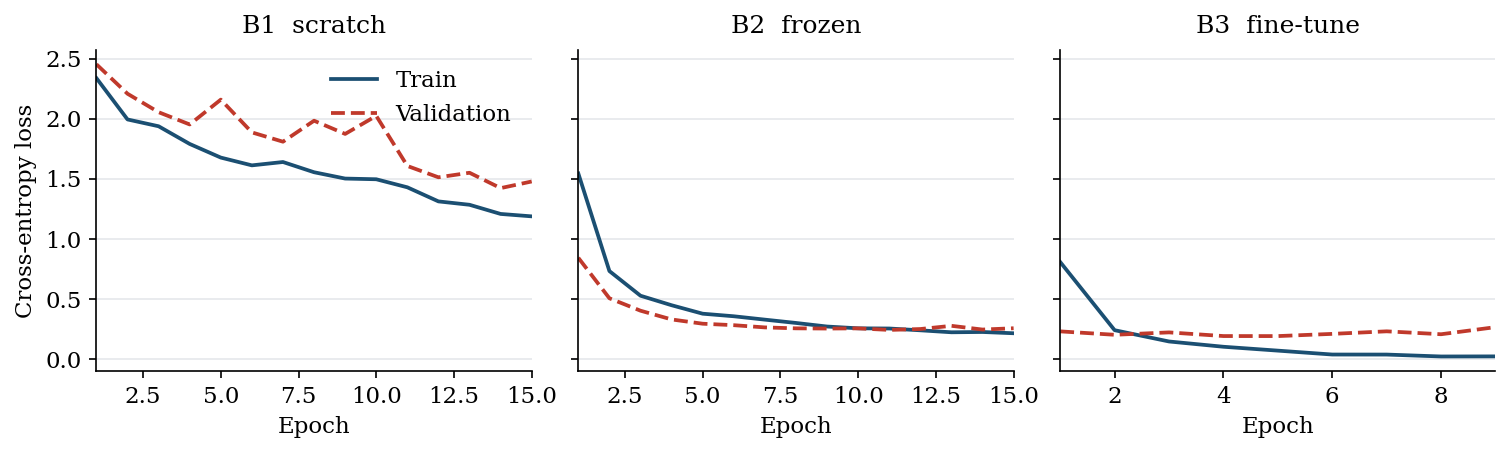

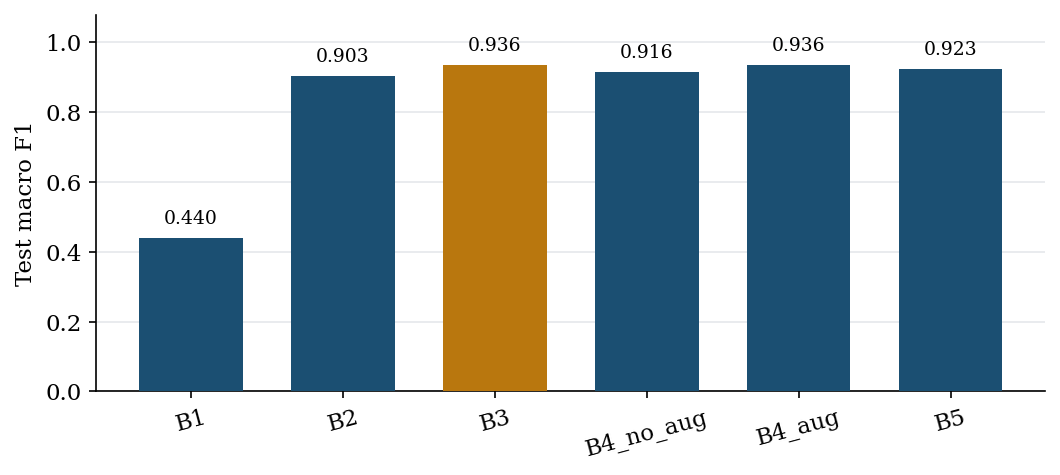

In [6]:
# Loss curves for B1, B2, and B3, then test macro F1. The best bar is highlighted.
labels = {"B1": "B1  scratch", "B2": "B2  frozen", "B3": "B3  fine-tune"}
fig, axes = plt.subplots(1, 3, figsize=(10.2, 3.15), sharey=True)
for axis, name in zip(axes, ["B1", "B2", "B3"]):
    part = epoch_logs[epoch_logs["condition"] == name]
    axis.plot(part["epoch"], part["train_loss"], color=TRAIN_COLOR, lw=1.8, label="Train")
    axis.plot(part["epoch"], part["val_loss"], color=VAL_COLOR, lw=1.8, ls="--", label="Validation")
    axis.set_title(labels[name], pad=8)
    axis.set_xlabel("Epoch")
    axis.set_xlim(part["epoch"].min(), part["epoch"].max())
    axis.grid(axis="y", color="#E5E8EB", lw=0.8)
    axis.set_axisbelow(True)
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend(loc="upper right")
fig.tight_layout()
fig.savefig(OUT_DIR / "loss_curves.pdf")
plt.show()

order = metrics["condition"].tolist()
scores = metrics["test_macro_f1"].tolist()
best_idx = int(np.argmax(scores))
colors = [BAR_HIGHLIGHT if i == best_idx else BAR_COLOR for i in range(len(scores))]
fig, axis = plt.subplots(figsize=(7.2, 3.3))
bars = axis.bar(order, scores, color=colors, width=0.68, zorder=3)
axis.set_ylabel("Test macro F1")
axis.set_ylim(0, 1.08)
axis.grid(axis="y", color="#E5E8EB", lw=0.8, zorder=0)
axis.set_axisbelow(True)
axis.tick_params(axis="x", labelrotation=15)
for bar, score in zip(bars, scores):
    axis.text(bar.get_x() + bar.get_width() / 2, score + 0.03, f"{score:.3f}", ha="center", va="bottom", fontsize=9)
fig.tight_layout()
fig.savefig(OUT_DIR / "f1_bars.pdf")
plt.show()


## 7. Failure cases

The best test macro F1 checkpoint is scored on the test set. Up to eight mistakes are saved with the true breed, the prediction, and the confidence.


best checkpoint B3


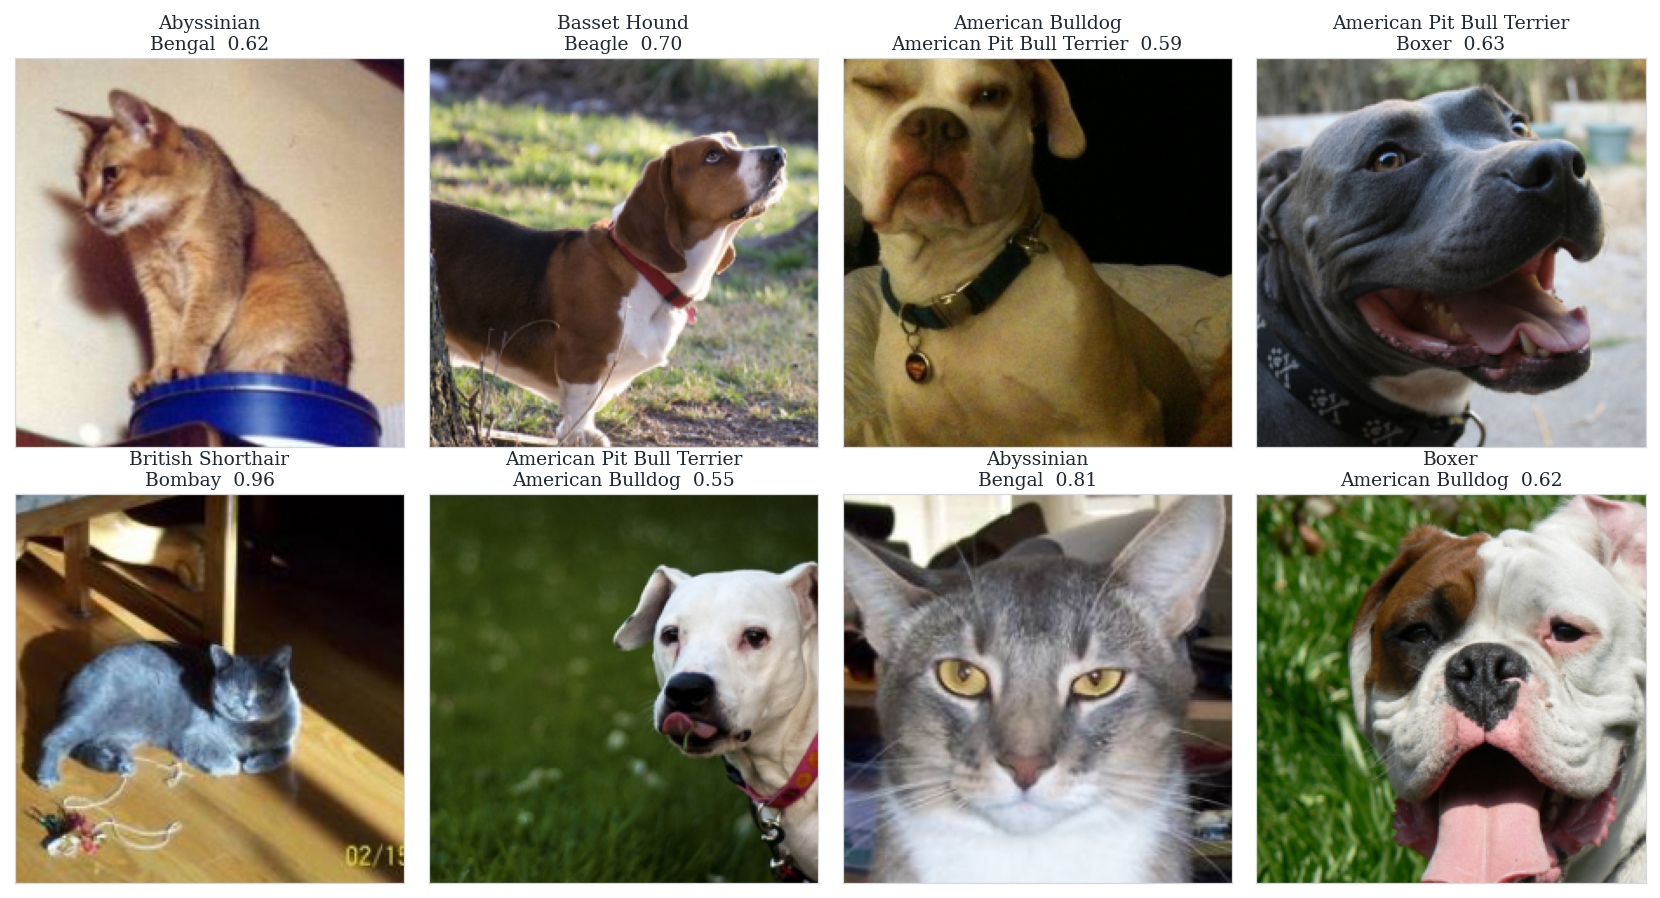

[{'true': 'Abyssinian', 'pred': 'Bengal', 'confidence': 0.621}, {'true': 'Basset Hound', 'pred': 'Beagle', 'confidence': 0.701}, {'true': 'American Bulldog', 'pred': 'American Pit Bull Terrier', 'confidence': 0.59}, {'true': 'American Pit Bull Terrier', 'pred': 'Boxer', 'confidence': 0.633}, {'true': 'British Shorthair', 'pred': 'Bombay', 'confidence': 0.962}, {'true': 'American Pit Bull Terrier', 'pred': 'American Bulldog', 'confidence': 0.555}, {'true': 'Abyssinian', 'pred': 'Bengal', 'confidence': 0.812}, {'true': 'Boxer', 'pred': 'American Bulldog', 'confidence': 0.622}]


In [8]:
# Eight test mistakes of the best checkpoint: true breed, prediction, confidence.
best_name = metrics.sort_values(["test_macro_f1", "val_acc"], ascending=False).iloc[0]["condition"]
best_model = trained_models[best_name]
print("best checkpoint", best_name)

mean = torch.tensor(IMAGENET_MEAN)[:, None, None]
std = torch.tensor(IMAGENET_STD)[:, None, None]
shown = 0
records = []
fig, axes = plt.subplots(2, 4, figsize=(11.2, 6.1))
fig.patch.set_facecolor("white")
axes = axes.ravel()
best_model.eval()
with torch.no_grad():
    for images, targets in test_loader:
        logits = best_model(images.to(DEVICE))
        probs = torch.softmax(logits, dim=1)
        conf, pred = probs.max(dim=1)
        for i in range(images.size(0)):
            if int(pred[i]) == int(targets[i]):
                continue
            image = (images[i].cpu() * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()
            true_name = index_to_label[int(targets[i])]
            pred_name = index_to_label[int(pred[i])]
            score = float(conf[i])
            records.append({"true": true_name, "pred": pred_name, "confidence": round(score, 3)})
            axes[shown].imshow(image)
            axes[shown].set_title(f"{true_name}\n{pred_name}  {score:.2f}", fontsize=9, color="#1C2833", pad=4)
            axes[shown].set_xticks([])
            axes[shown].set_yticks([])
            for spine in axes[shown].spines.values():
                spine.set_visible(True)
                spine.set_color("#D5D8DC")
                spine.set_linewidth(0.6)
            shown += 1
            if shown == 8:
                break
        if shown == 8:
            break
for axis in axes[shown:]:
    axis.axis("off")
fig.tight_layout()
fig.savefig(OUT_DIR / "failures.pdf")
pd.DataFrame(records).to_csv(OUT_DIR / "failures.csv", index=False)
plt.show()
print(records)


## 8. `layer4` before and after fine-tuning

A hook reads `layer4` on B2 and on B3 for one test image B3 gets right and one it gets wrong. Each heatmap is the mean over channels. A similar blob on a missed breed means those two breeds still share the same cues.


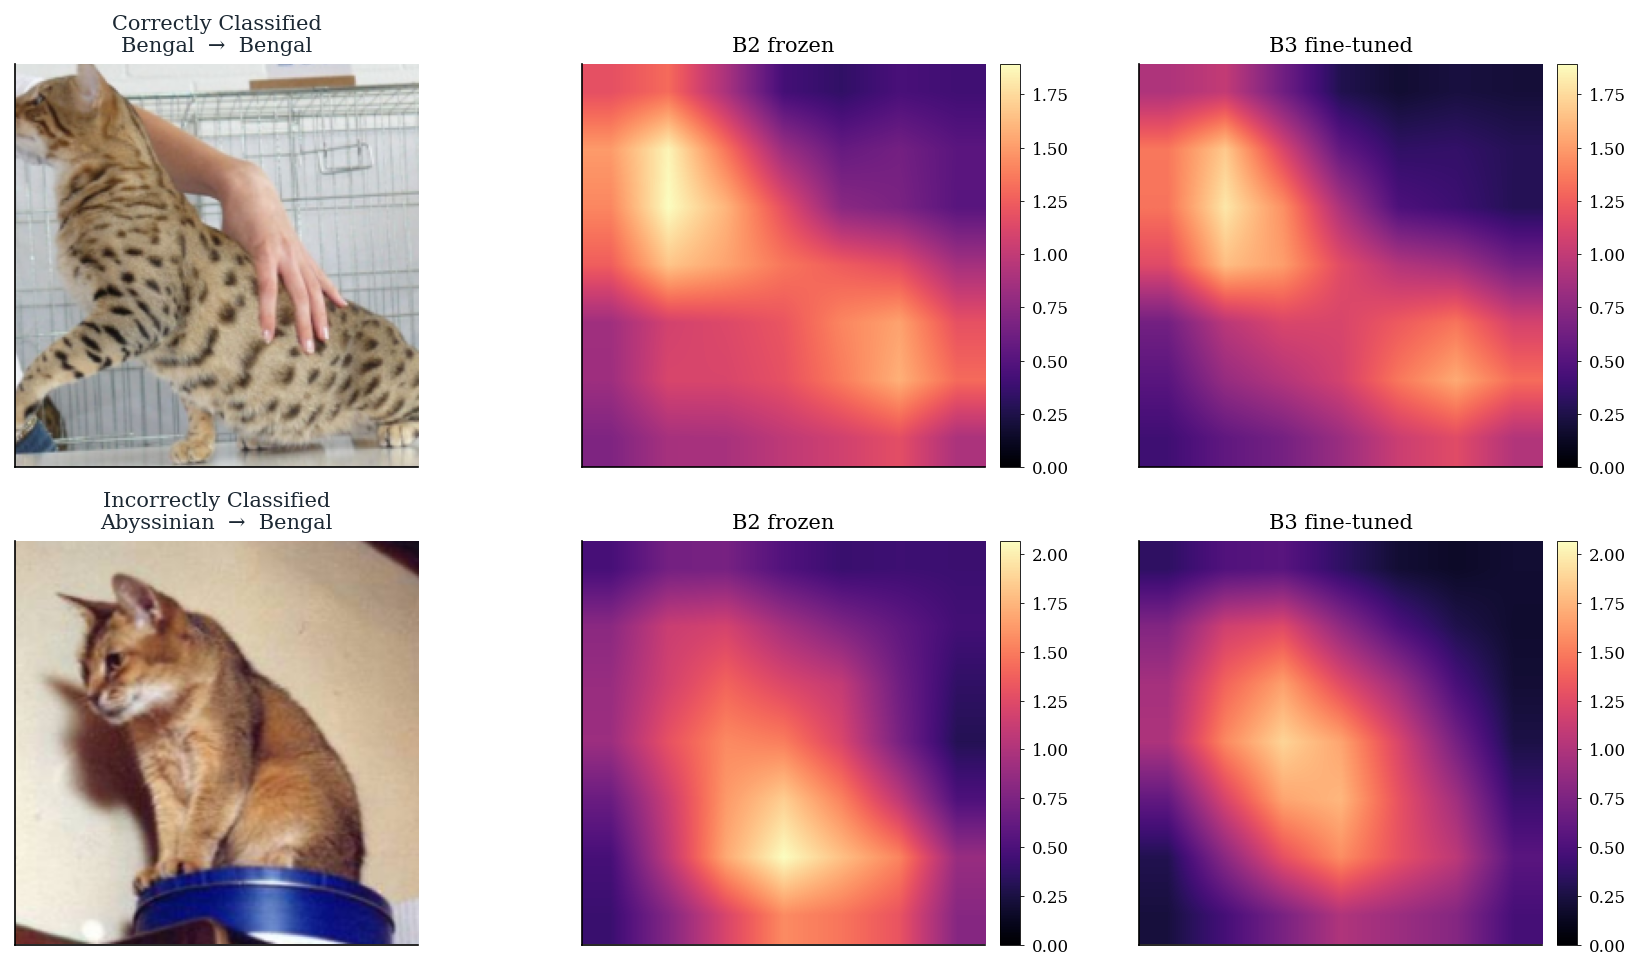

In [11]:
# B2 is layer4 before fine-tuning. B3 is the same block after it was trained.
model_before = trained_models["B2"]
model_after = trained_models["B3"]
model_before.eval()
model_after.eval()

activations = {}

def get_activation(name):
    def hook(module, inputs, output):
        activations[name] = output.detach()
    return hook

handle_before = model_before.layer4.register_forward_hook(get_activation("before"))
handle_after = model_after.layer4.register_forward_hook(get_activation("after"))

correct_img = incorrect_img = None
correct_target = correct_pred = incorrect_target = incorrect_pred = None

with torch.no_grad():
    for images, targets in test_loader:
        preds = model_after(images.to(DEVICE)).argmax(dim=1).cpu()
        for i in range(len(targets)):
            if preds[i] == targets[i] and correct_img is None:
                correct_img = images[i:i + 1]
                correct_target = int(targets[i])
                correct_pred = int(preds[i])
            elif preds[i] != targets[i] and incorrect_img is None:
                incorrect_img = images[i:i + 1]
                incorrect_target = int(targets[i])
                incorrect_pred = int(preds[i])
        if correct_img is not None and incorrect_img is not None:
            break

if correct_img is None or incorrect_img is None:
    raise RuntimeError("Need one correct and one incorrect test image to draw layer4 maps.")

samples = [
    ("Correctly Classified", correct_img, correct_target, correct_pred),
    ("Incorrectly Classified", incorrect_img, incorrect_target, incorrect_pred),
]

fig, axes = plt.subplots(2, 3, figsize=(11.4, 6.6))
fig.patch.set_facecolor("white")
mean = torch.tensor(IMAGENET_MEAN)[:, None, None]
std = torch.tensor(IMAGENET_STD)[:, None, None]

for row_idx, (status, img, target, pred) in enumerate(samples):
    single_image = img.to(DEVICE)
    with torch.no_grad():
        model_before(single_image)
        model_after(single_image)
    map_before = activations["before"][0].mean(dim=0).cpu().numpy()
    map_after = activations["after"][0].mean(dim=0).cpu().numpy()
    orig_img = (img[0].cpu() * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

    shared = max(float(map_before.max()), float(map_after.max()))
    axes[row_idx, 0].imshow(orig_img)
    axes[row_idx, 0].set_title(
        f"{status}\n{index_to_label[target]}  →  {index_to_label[pred]}",
        fontsize=10,
        color="#1C2833",
    )
    axes[row_idx, 0].set_xticks([])
    axes[row_idx, 0].set_yticks([])

    im1 = axes[row_idx, 1].imshow(map_before, cmap="magma", interpolation="bilinear", vmin=0, vmax=shared)
    axes[row_idx, 1].set_title("B2 frozen", fontsize=10)
    axes[row_idx, 1].set_xticks([])
    axes[row_idx, 1].set_yticks([])
    bar1 = fig.colorbar(im1, ax=axes[row_idx, 1], fraction=0.046, pad=0.03)
    bar1.outline.set_linewidth(0.4)
    bar1.ax.tick_params(labelsize=8, width=0.4, length=2)

    im2 = axes[row_idx, 2].imshow(map_after, cmap="magma", interpolation="bilinear", vmin=0, vmax=shared)
    axes[row_idx, 2].set_title("B3 fine-tuned", fontsize=10)
    axes[row_idx, 2].set_xticks([])
    axes[row_idx, 2].set_yticks([])
    bar2 = fig.colorbar(im2, ax=axes[row_idx, 2], fraction=0.046, pad=0.03)
    bar2.outline.set_linewidth(0.4)
    bar2.ax.tick_params(labelsize=8, width=0.4, length=2)

handle_before.remove()
handle_after.remove()
fig.tight_layout()
fig.savefig(OUT_DIR / "layer4_maps.png", dpi=150)
plt.show()


## 9. Download

Zips `outputs/` and, in Colab, starts a download: `metrics.csv`, `epoch_logs.csv`, `failures.csv`, `loss_curves.pdf`, `f1_bars.pdf`, `failures.pdf`, and `layer4_maps.png`.


In [12]:
# Zip the output folder and download it in Colab.
import shutil

archive = shutil.make_archive(str(ROOT / "tugas05_outputs"), "zip", OUT_DIR)
print("Saved", archive)
print("Copy these files into the report folder before compiling the PDF:")
for path in sorted(OUT_DIR.iterdir()):
    print(" -", path.name)

try:
    from google.colab import files
    files.download(archive)
except ImportError:
    print("Not running in Colab. Download the zip from", archive)


Saved /content/tugas05_outputs.zip
Copy these files into the report folder before compiling the PDF:
 - epoch_logs.csv
 - f1_bars.pdf
 - failures.csv
 - failures.pdf
 - layer4_maps.png
 - loss_curves.pdf
 - metrics.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>